# DQN (Deep Q Network) Notebook

In [1]:
import sys
sys.path.append("../../Reinforcement-Learning-Policy-Sparsification-and-Decomposition")

In [2]:
import gym, warnings, os, torch, copy, random, gc, json
import torch.nn as nn
import numpy as np
import pandas as pd
from models import PolicyNet, SparsePolicyNet
from rl_utils.dqn import ReplayMemory, train
from  utils import (
    xavier_init_weights, 
    save_model_params, 
    plot_train_performance, 
    plot_result_dataframe,
    run_evaluation,
)
from typing import Union, Optional

warnings.filterwarnings("ignore")
os.environ["ENV_SEED"] = "3407"
RENDER_MODE_ON_EVAL = None
torch.set_default_dtype(torch.float32)

In [3]:
SEED = int(os.environ["ENV_SEED"])
random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
np.random.seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [4]:
#replay memory parameters
replay_memory_capacity = 10_000
batch_size = 32

#dense_optimizer hyperparameters
lr = 2.5e-5

#policy hyperparameters
gamma = 0.99
min_epsilon = 0.0
max_epsilon = 1.0
episodes = 2_000
target_network_update_step = 5
hidden_size = 128
max_episode_reward = -100
max_episode_steps = 500


env_name = "Acrobot-v1"
train_env = gym.make(env_name)
results_dir = "../sparsification_results"

#model hyper-parameters
observation_space = train_env.observation_space._shape[0]
action_space = train_env.action_space.n

replay_memory = ReplayMemory(replay_memory_capacity)

sparsity_penalty_coefs = np.array([1e-05, 5e-5, 1e-4, 5e-4, 1e-3, 5e-3, 1e-2, 5e-2, 1e-1, 5e-1])

REWARDS_DICT = dict()

In [5]:
def run_train(
        policy_agent: Union[PolicyNet, SparsePolicyNet], 
        policy_target: Union[PolicyNet, SparsePolicyNet],
        policy_optimizer: torch.optim.Optimizer,
        policy_weights_filename: Optional[str]=None,
        save_best_weights: bool=True,
        sparse_penalty_coef: Optional[float]=None,
        plot_performance: bool=True,
    ):
    
    os.makedirs("../params", exist_ok=True)
    train_env = gym.make(env_name)
    

    label = "dense"
    if isinstance(policy_agent, SparsePolicyNet):
        assert sparse_penalty_coef is not None
        label = f"sparse({sparse_penalty_coef})"

    if save_best_weights:
        assert policy_weights_filename is not None

    if isinstance(policy_agent, SparsePolicyNet) and sparse_penalty_coef is not None:
        lossfunc = lambda pred, target : nn.MSELoss()(pred[0], target) + ((sparse_penalty_coef * pred[1]) / batch_size)
    else:
        lossfunc = nn.MSELoss()
        
    try:
        train_performance, best_rewards = train(
            train_env,
            policy_agent,
            policy_target,
            replay_memory,
            lossfunc,
            policy_optimizer,
            episodes=episodes,
            batch_size=batch_size,
            gamma=gamma,
            min_epsilon=min_epsilon,
            max_epsilon=max_epsilon,
            max_episode_reward=max_episode_reward,
            max_episode_steps=max_episode_steps,
            continue_after_max_reward=False,
            target_network_update_step=target_network_update_step,
            weights_filename=policy_weights_filename,
            save_best_weights=save_best_weights,
            verbose=False,
            close_env=True,
        )
        replay_memory.clear()

        REWARDS_DICT[label] = train_performance["rewards"]
        if plot_performance:
            plot_train_performance(train_performance, best_rewards)

        convergence_steps = len(train_performance["rewards"])
        
        return convergence_steps

    except KeyboardInterrupt:
        train_env.close()

## Train and Evaluate Dense Policy

 39%|███▉      | 777/2000 [34:02<53:34,  2.63s/it]  


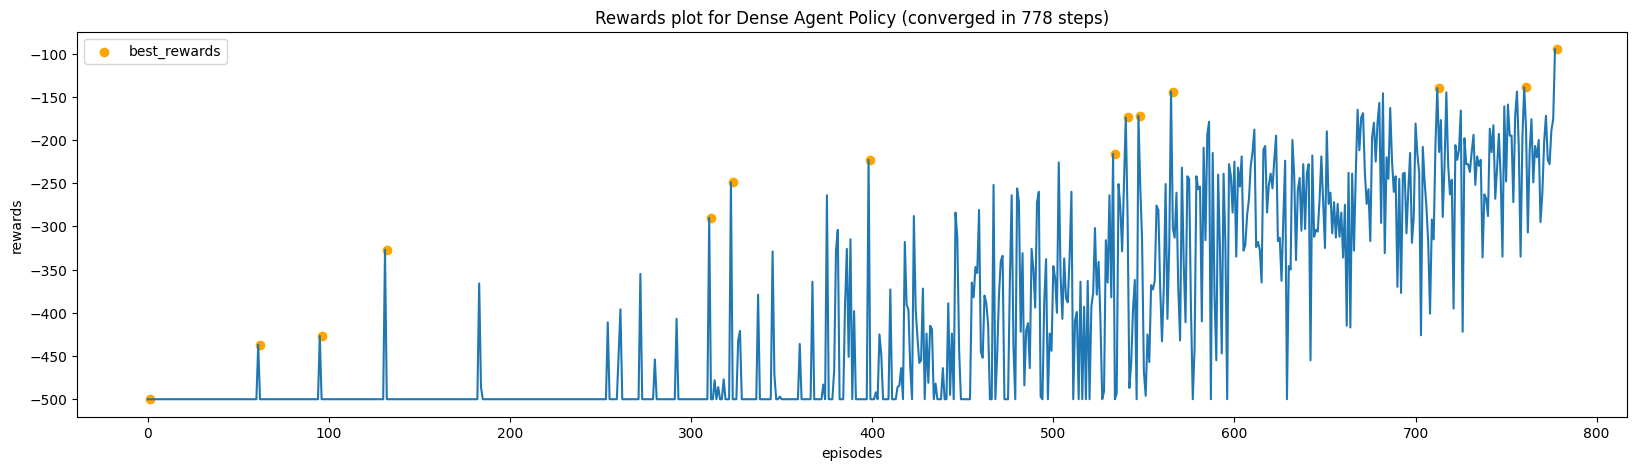

Evaluation reward of policy: -74.0
Average entropy of policy: 0.0068467


(-74.0, 0.00684668847322464)

In [6]:
dense_policy_agent = PolicyNet(observation_space, action_space, hidden_size).to(os.getenv("DEVICE"))
dense_policy_agent.apply(xavier_init_weights)
dense_policy_target = copy.deepcopy(dense_policy_agent).to(os.getenv("DEVICE"))
dense_optimizer = torch.optim.Adam(dense_policy_agent.parameters(), lr=lr)
weights_filename = f"{env_name}_DQN_dense_agent.pth.tar"

run_train(
    dense_policy_agent,
    dense_policy_target,
    dense_optimizer,
    weights_filename,
    plot_performance=True
)

dense_policy_agent.load_state_dict(torch.load(os.path.join(f"../params/{weights_filename}")))
run_evaluation(gym.make(env_name, render_mode=RENDER_MODE_ON_EVAL), dense_policy_agent, verbose=True)

## Train and Evaluate Sparse Policy Against Different Sparsity Coefficents

Training sparse policy with sparsity coef: 1e-05



 54%|█████▍    | 1078/2000 [1:15:04<1:04:13,  4.18s/it]


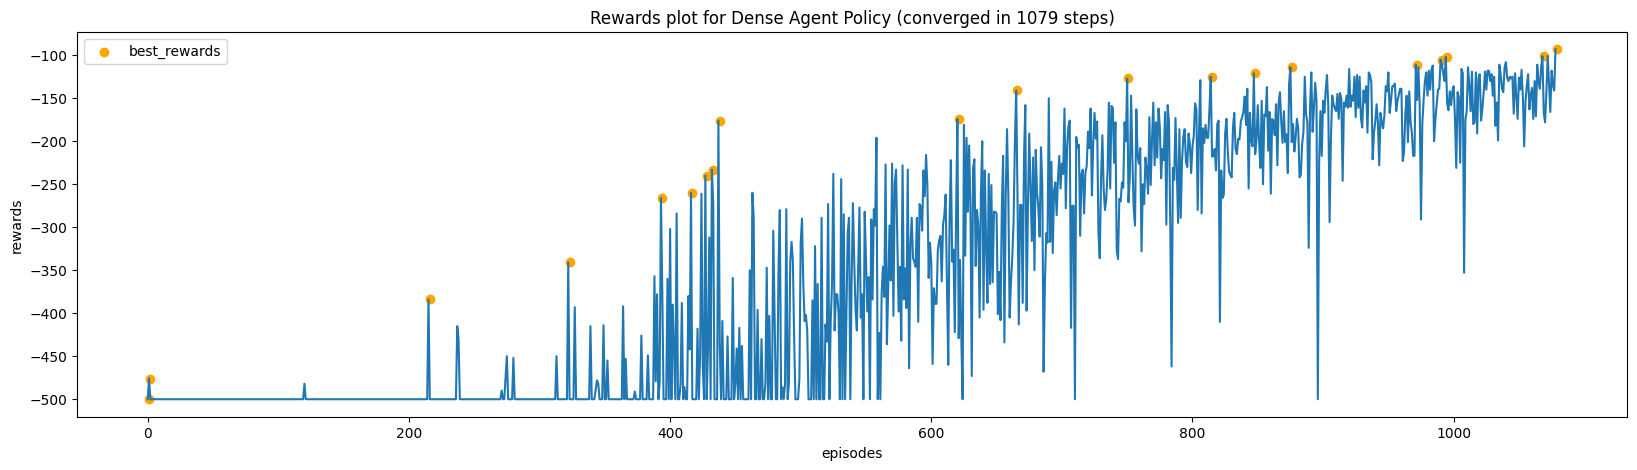

Training sparse policy with sparsity coef: 5e-05



 49%|████▉     | 982/2000 [1:04:47<1:07:09,  3.96s/it]


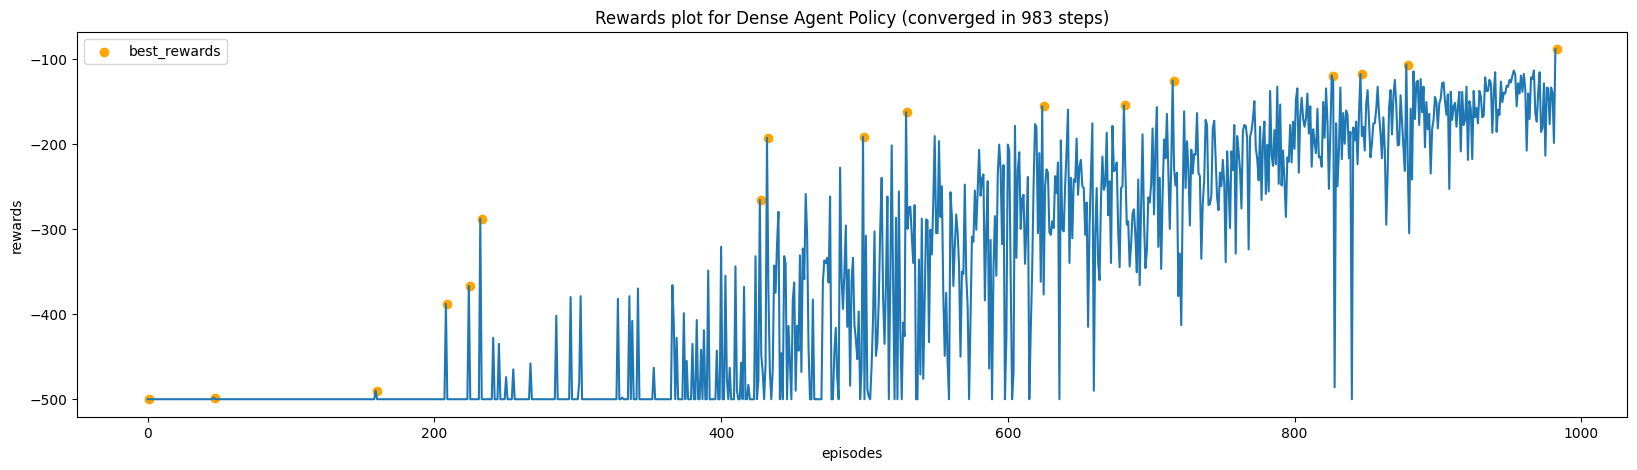

Training sparse policy with sparsity coef: 0.0001



 46%|████▌     | 916/2000 [59:16<1:10:09,  3.88s/it]


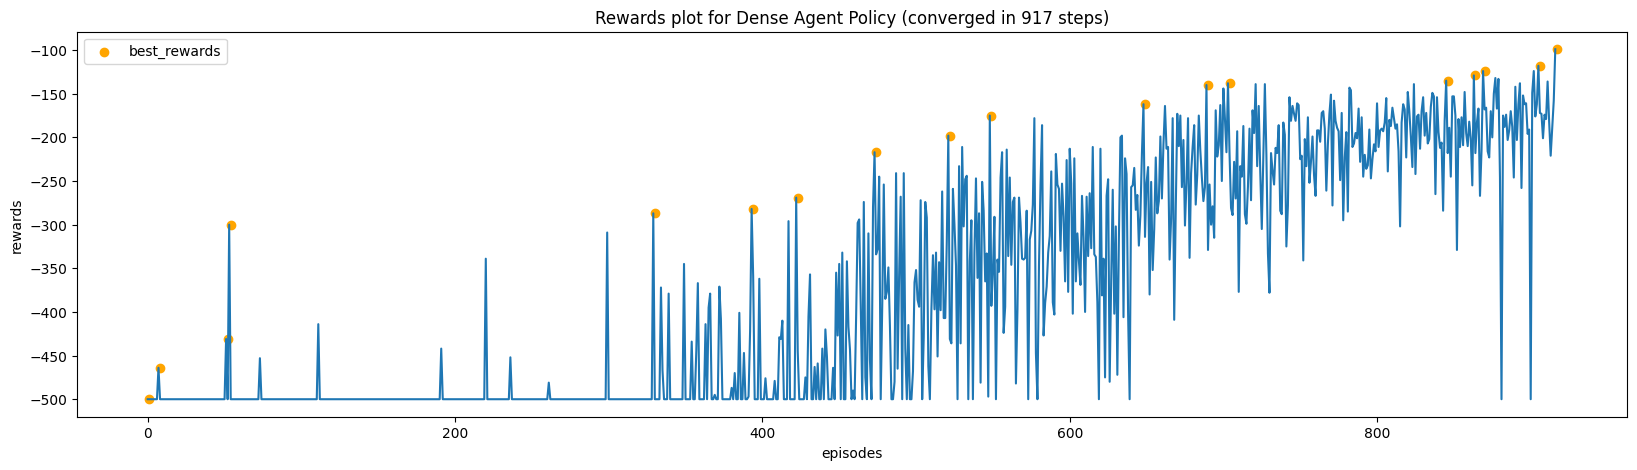

Training sparse policy with sparsity coef: 0.0005



 49%|████▉     | 989/2000 [56:17<57:32,  3.42s/it]  


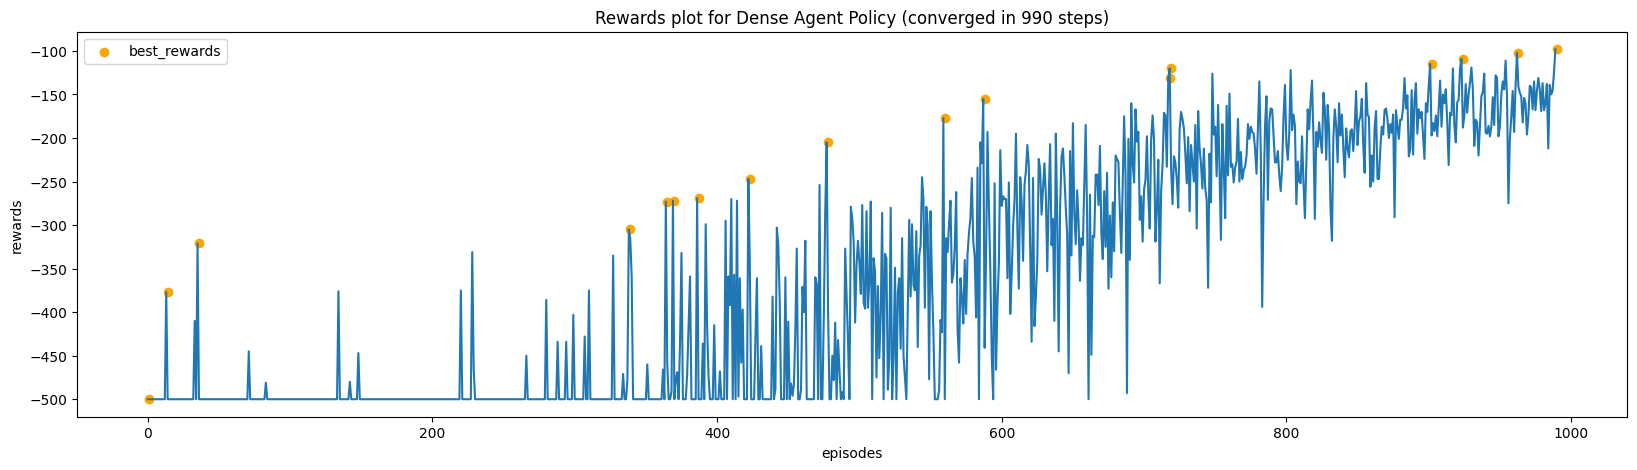

Training sparse policy with sparsity coef: 0.001



 44%|████▍     | 884/2000 [53:01<1:06:56,  3.60s/it]


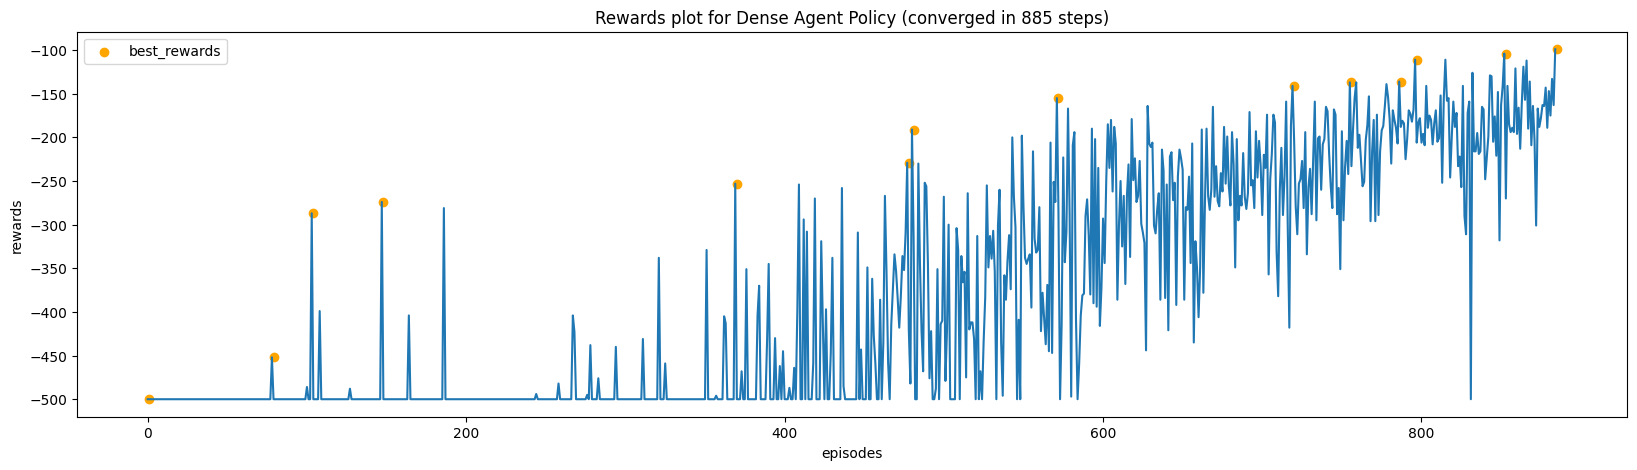

Training sparse policy with sparsity coef: 0.005



 46%|████▋     | 926/2000 [55:25<1:04:17,  3.59s/it]


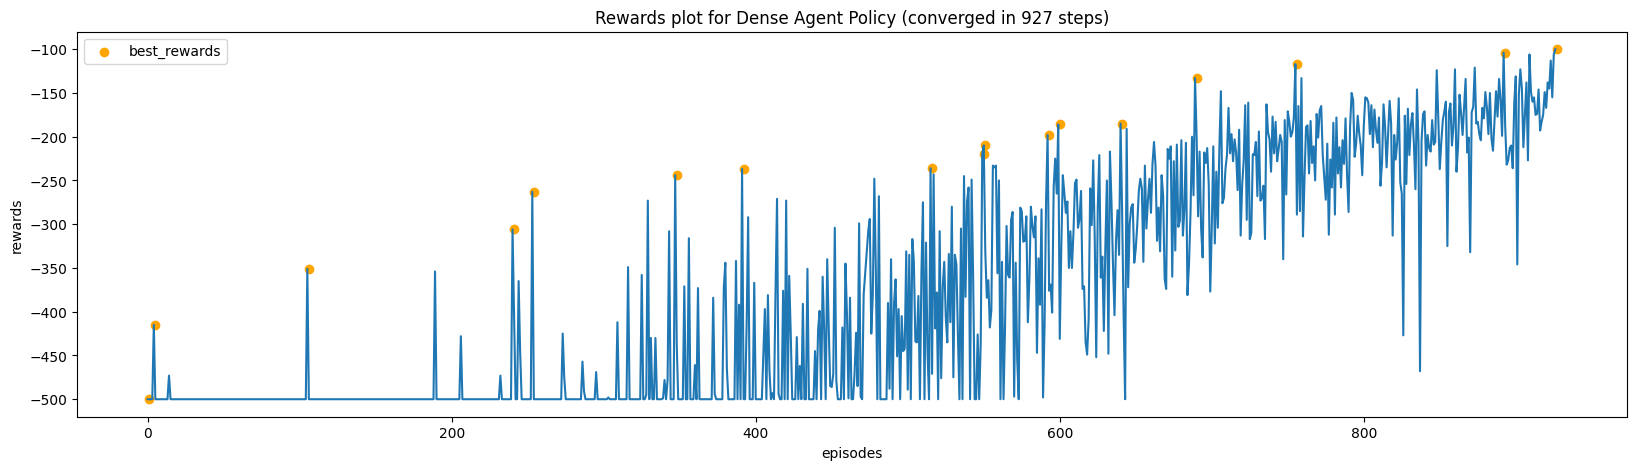

Training sparse policy with sparsity coef: 0.01



 44%|████▎     | 874/2000 [52:21<1:07:27,  3.59s/it]


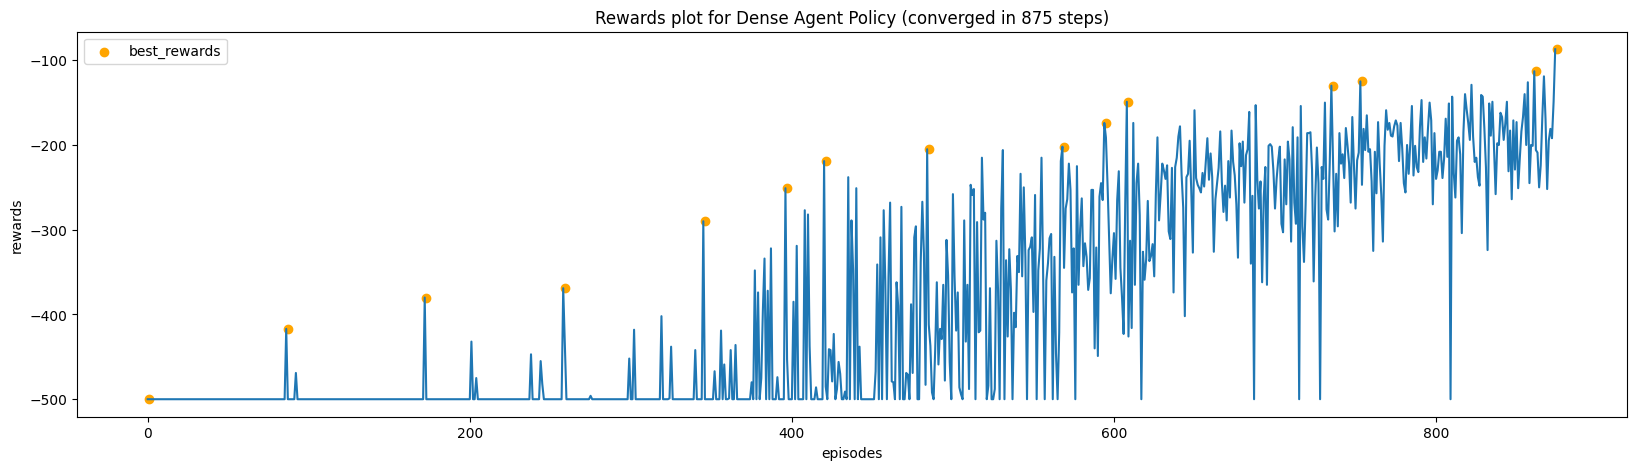

Training sparse policy with sparsity coef: 0.05



 50%|█████     | 1004/2000 [54:19<53:53,  3.25s/it] 


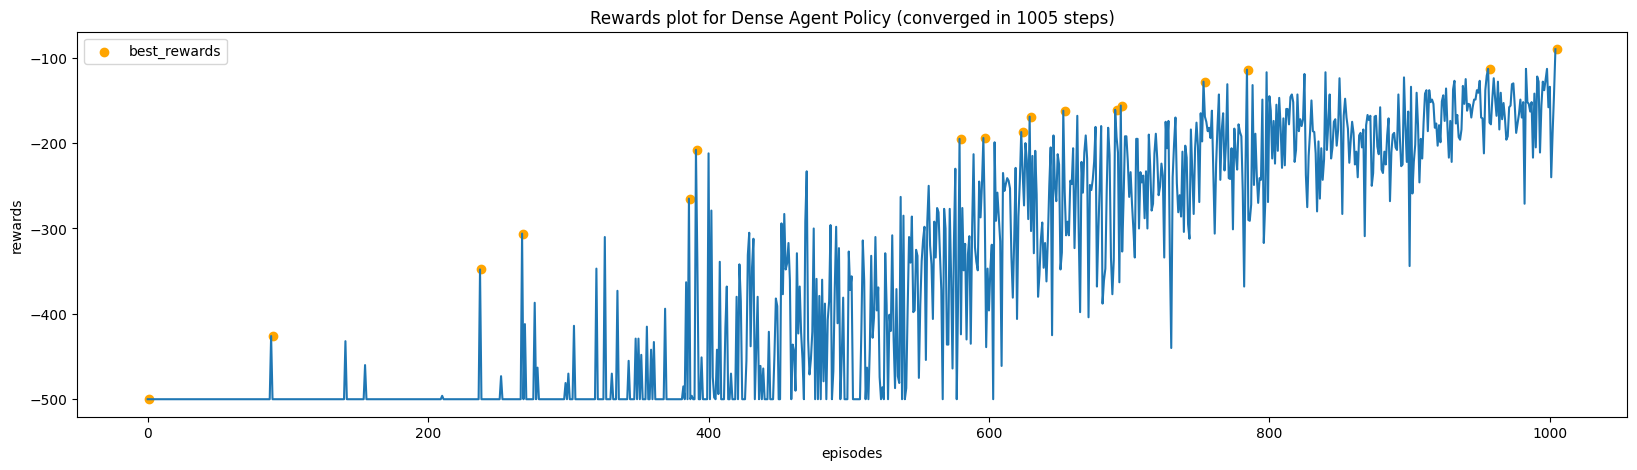

Training sparse policy with sparsity coef: 0.1



 53%|█████▎    | 1062/2000 [59:01<52:07,  3.33s/it] 


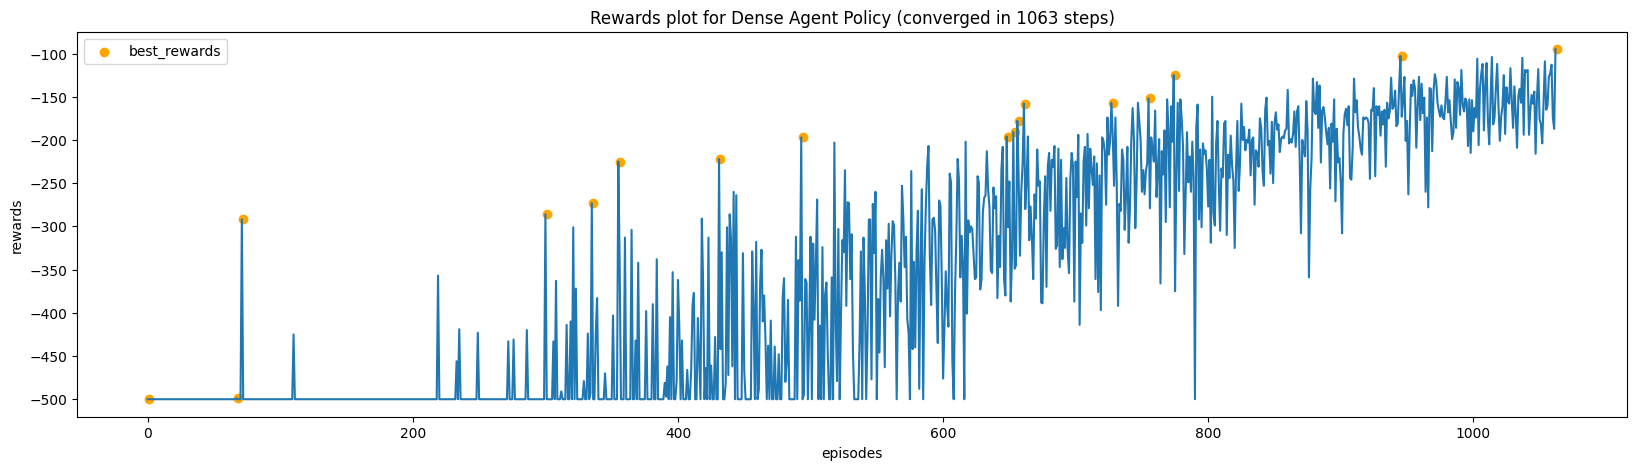

Training sparse policy with sparsity coef: 0.5



 54%|█████▎    | 1073/2000 [1:00:31<52:17,  3.38s/it]


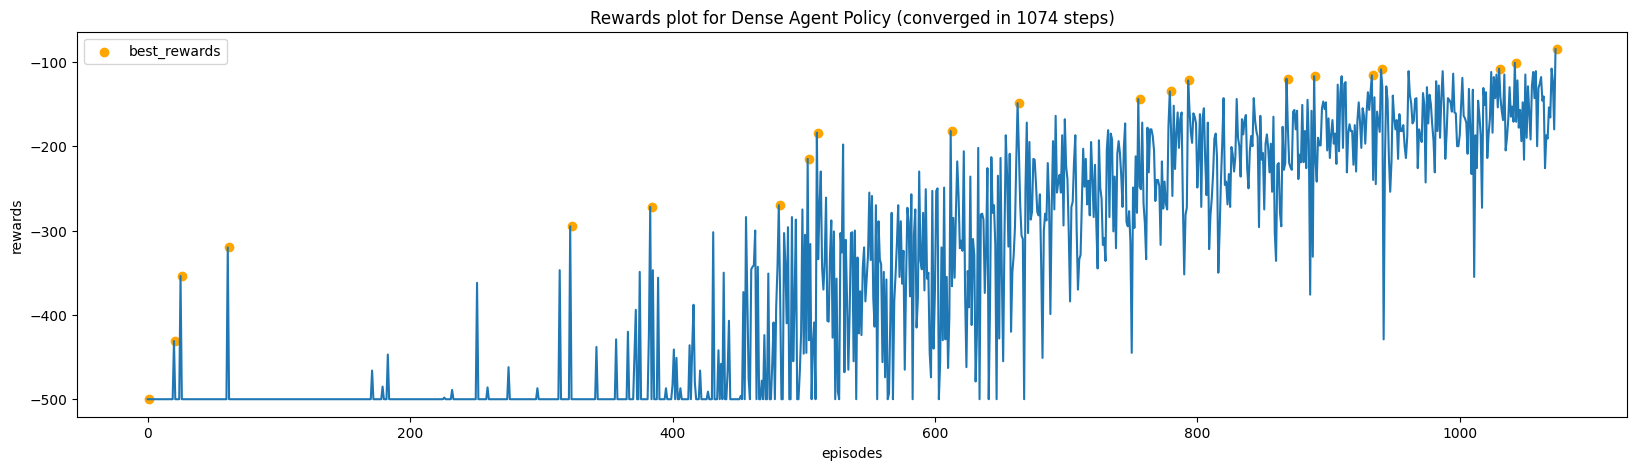

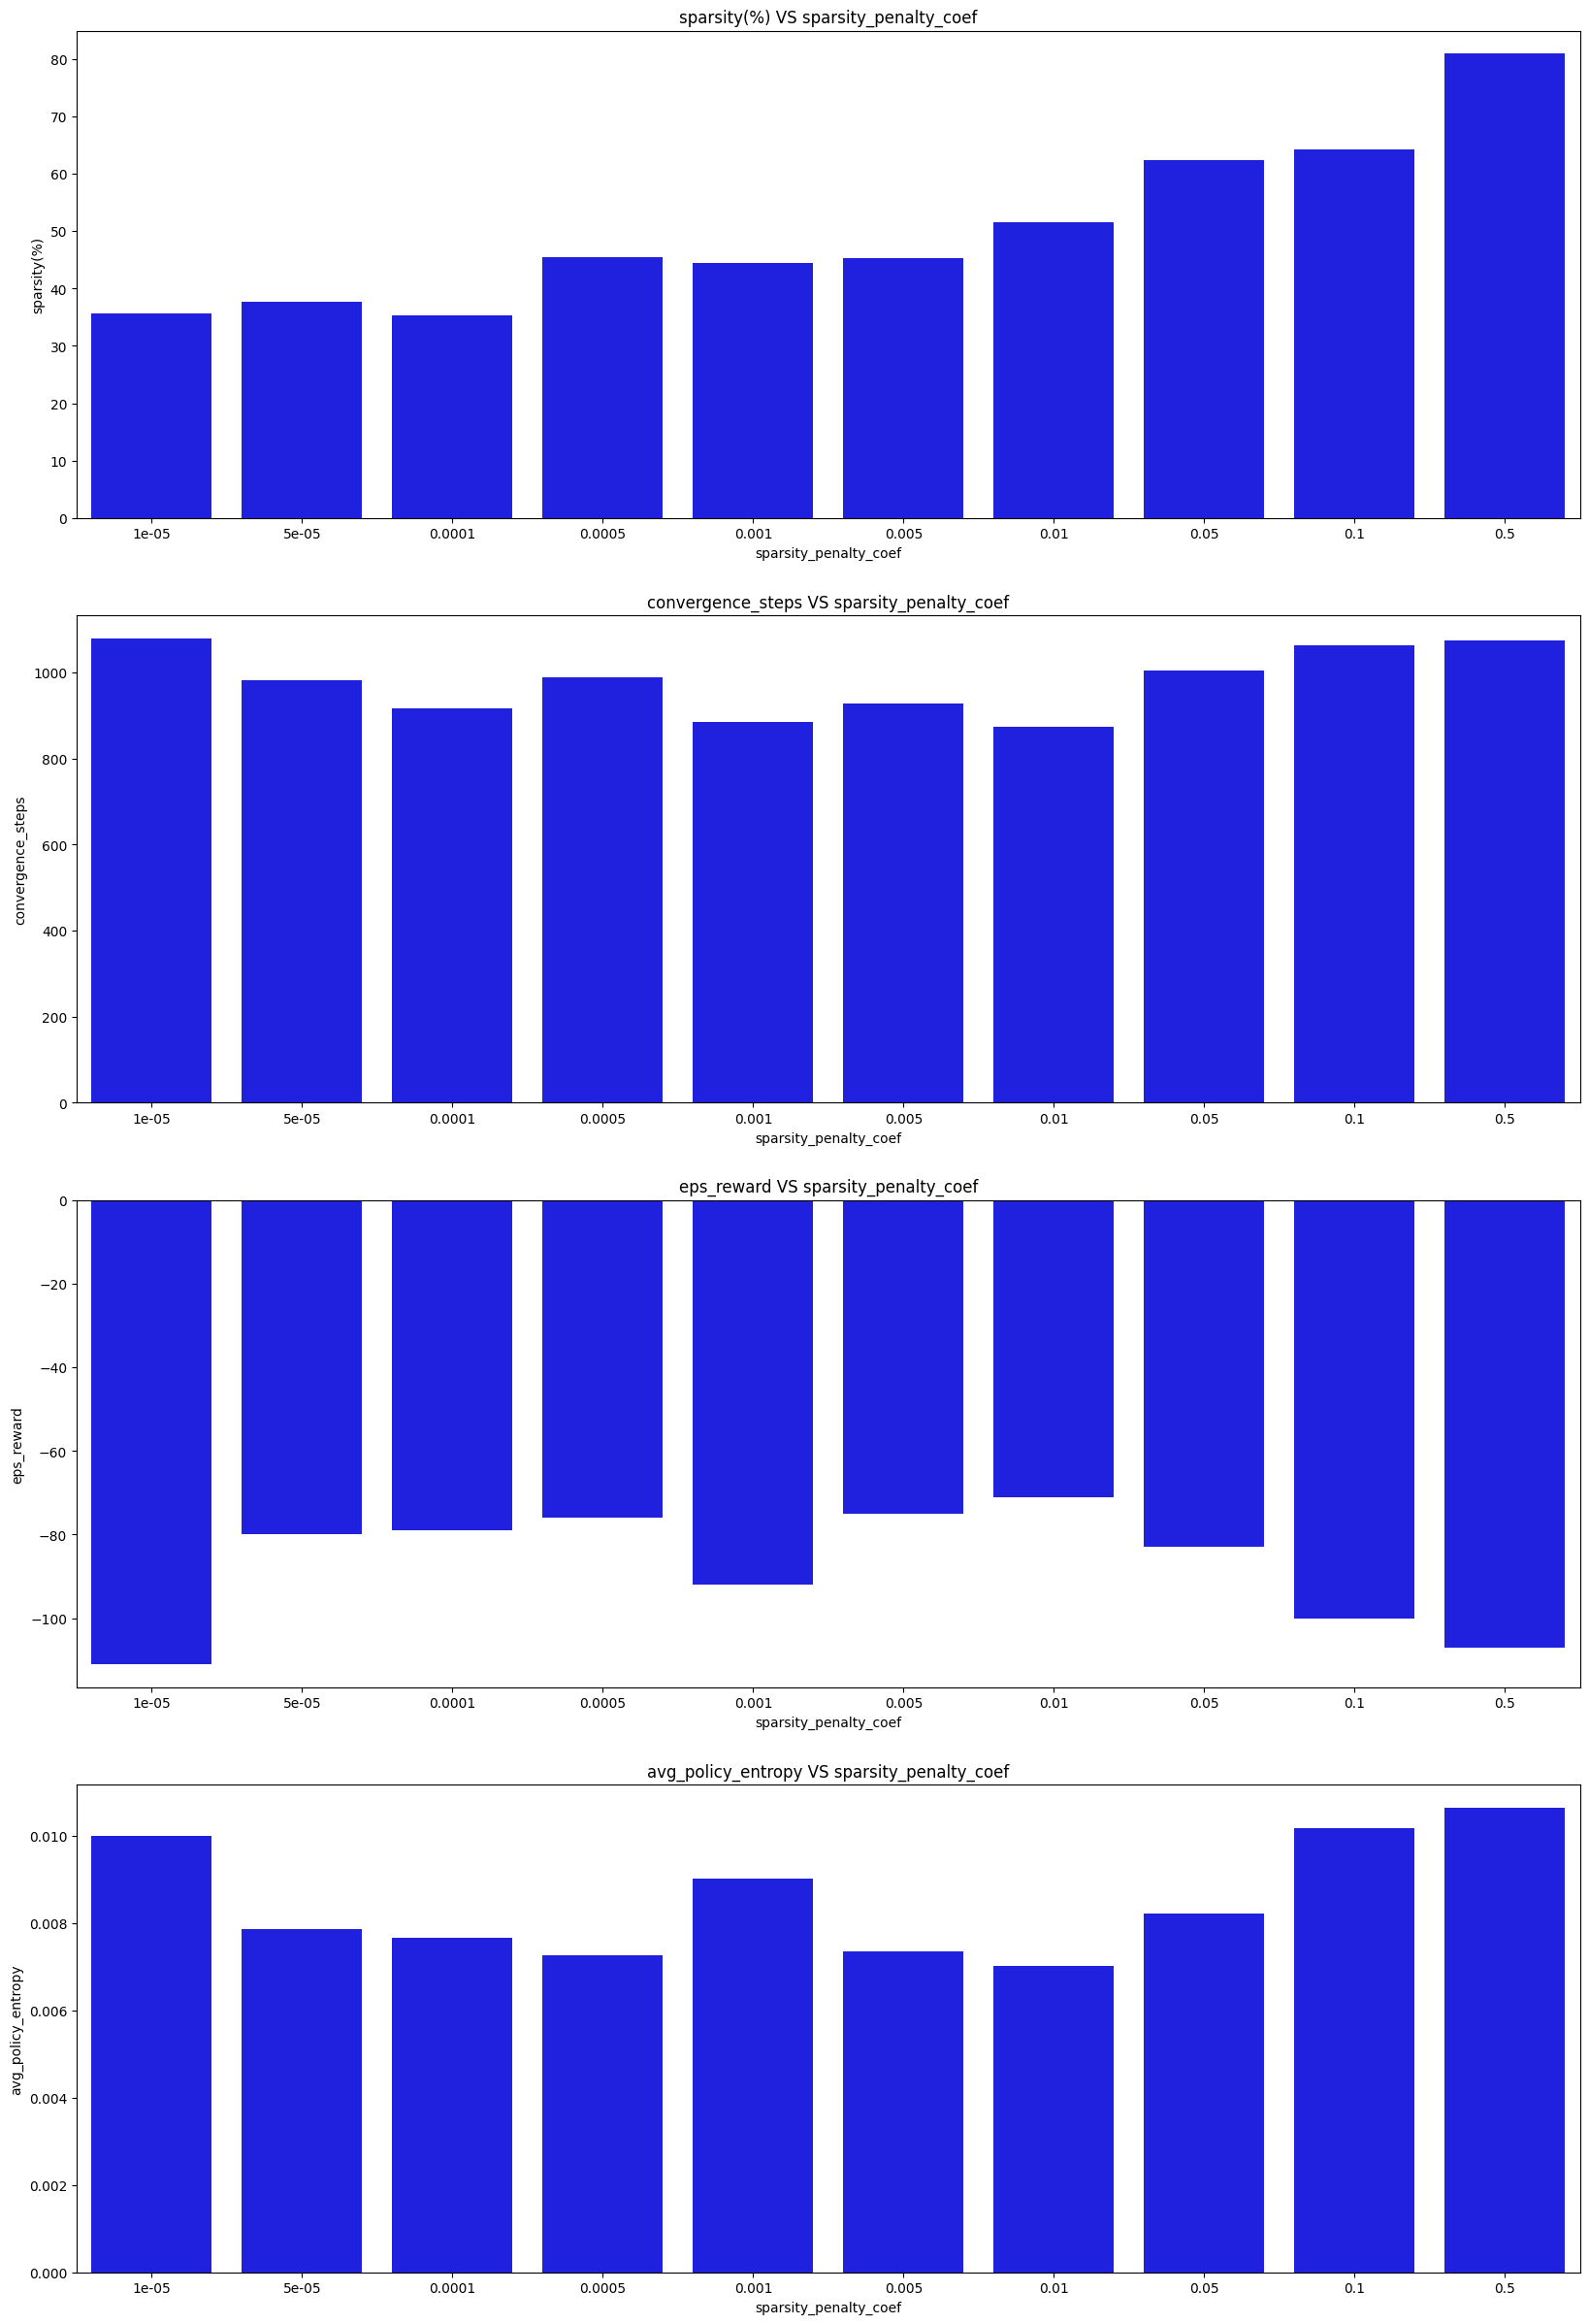

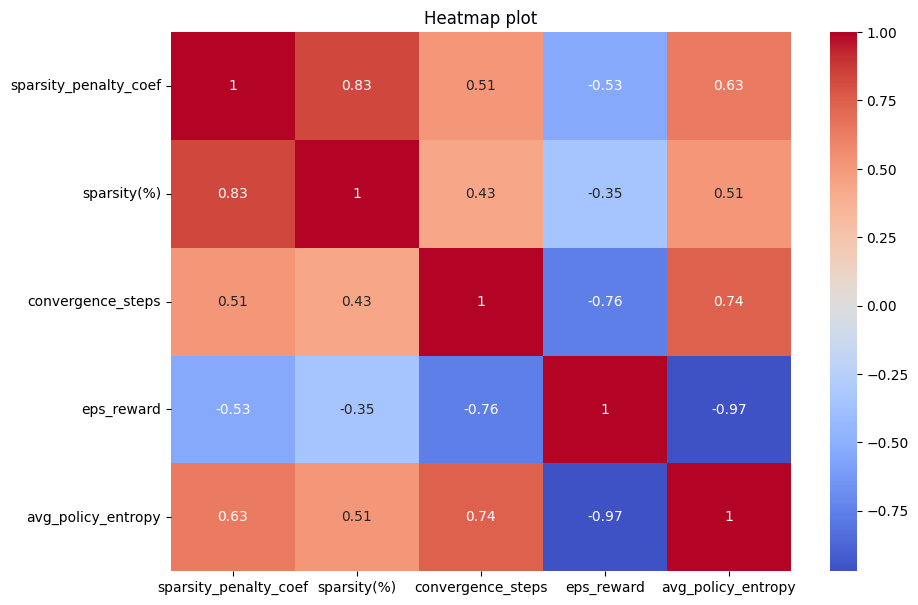

,sparsity_penalty_coef,sparsity(%),convergence_steps,eps_reward,avg_policy_entropy
0,0.00001,35.662842,1079,-111.0,0.009990
1,0.00005,37.680054,983,-80.0,0.007864
2,0.00010,35.304769,917,-79.0,0.007660
3,0.00050,45.475260,990,-76.0,0.007262
4,0.00100,44.508870,885,-92.0,0.009024
5,0.00500,45.319621,927,-75.0,0.007350
6,0.01000,51.633708,875,-71.0,0.007018
7,0.05000,62.417603,1005,-83.0,0.008230
8,0.10000,64.335124,1063,-100.0,0.010184
9,0.50000,80.918376,1074,-107.0,0.010635


In [7]:
result = dict()
result["sparsity_penalty_coef"] = []
result["sparsity(%)"] = []
result["convergence_steps"] = []
result["eps_reward"] = []
result["avg_policy_entropy"] = []

weights_filename = f"{env_name}_DQN_sparse_agent.pth.tar"
best_score = -np.inf
best_model_idx = None

for idx, coef in enumerate(sparsity_penalty_coefs):
    sparse_policy_agent = SparsePolicyNet(
        observation_space, 
        action_space, 
        hidden_size, 
        sparsity_on_eval=True).to(os.getenv("DEVICE"))
    sparse_policy_agent.apply(xavier_init_weights)

    sparse_policy_target = SparsePolicyNet(
        observation_space, 
        action_space, 
        hidden_size, 
        sparsity_on_eval=True).to(os.getenv("DEVICE"))
    sparse_policy_target.load_state_dict(sparse_policy_agent.state_dict())

    sparse_optimizer = torch.optim.Adam(sparse_policy_agent.parameters(), lr=lr)

    print(f"Training sparse policy with sparsity coef: {coef}\n")
    
    _weights_filename = f"{idx}_{weights_filename}"
    convergence_steps = run_train(
        sparse_policy_agent, 
        sparse_policy_target, 
        sparse_optimizer, 
        _weights_filename,
        sparse_penalty_coef=coef,
        plot_performance=True
    )
    sparse_policy_agent.load_state_dict(torch.load(os.path.join(f"../params/{_weights_filename}")))
    eps_reward, avg_policy_entropy = run_evaluation(
        gym.make(env_name, render_mode=RENDER_MODE_ON_EVAL), 
        sparse_policy_agent,
        verbose=False
    )
    weight_sparsity = sparse_policy_agent.compute_weight_sparsity()[1] * 100
    score = eps_reward + (weight_sparsity)

    if score > best_score:
        best_score = score
        best_model_idx = idx

    result["sparsity_penalty_coef"].append(coef)
    result["sparsity(%)"].append(weight_sparsity)
    result["convergence_steps"].append(convergence_steps)
    result["eps_reward"].append(eps_reward)
    result["avg_policy_entropy"].append(avg_policy_entropy)

    del sparse_policy_agent, sparse_policy_target, sparse_optimizer
    gc.collect()
    torch.cuda.empty_cache()

for i in range(len(sparsity_penalty_coefs)):
    if i == best_model_idx:
        os.rename(f"../params/{i}_{weights_filename}", f"../params/{weights_filename}")
        continue
    os.remove(f"../params/{i}_{weights_filename}")

result = pd.DataFrame(result)
plot_result_dataframe(result, x_axis="sparsity_penalty_coef", figsize=(20, 30))
os.makedirs(results_dir, exist_ok=True)
result.to_csv(os.path.join(results_dir, f"{env_name}_DQN_sparsification_results.csv"), index=False)
result

In [ ]:
with open(os.path.join(results_dir, f"{env_name}_DQN_rewards.json"), "w") as f:
    json.dump(REWARDS_DICT, f, indent=4)